[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Barnabas4444/ProjectGrazingCow/blob/main/data_preparation.ipynb)

This is the way how we deal with the original 1 GB dataset, it is uploaded on Google Drive<br>
import os<br>
from pathlib import Path<br>
from google.colab import drive<br>

drive.mount('/content/drive')<br>

Here it changes the working directory to our project folder<br>
os.chdir('/content/drive/MyDrive/Project Grazing Cow/Deep_learning_Python_alapon')<br>
DATA_DIR = Path.cwd()

In [ ]:
from pathlib import Path
import random

# Packages for visualization
import matplotlib.pyplot as plt
from PIL import Image
import seaborn as sns

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split

for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)
import os

# Check whether we are on Google Colab
if 'google.colab' in str(get_ipython()):
  print('Google Colab environment detected. Cloning repository...')
  # Cloning the repo (if it doesn't exist yet)
  if not Path('ProjectGrazingCow').exists():
    !git clone https://github.com/Barnabas4444/ProjectGrazingCow.git
  # Enter the folder of the project
  os.chdir('/content/ProjectGrazingCow')

DATA_DIR = Path.cwd()
print(f'Munkam mappa beállítva: {DATA_DIR}')
DATA_DIR = Path.cwd()
IMAGE_SIZE = 320
BATCH_SIZE = 16
SEED = 42
TARGETS = ['Dry_Green_g', 'Dry_Dead_g', 'Dry_Clover_g', 'GDM_g', 'Dry_Total_g']
TARGET_WEIGHTS = tf.constant([0.1, 0.1, 0.1, 0.2, 0.5], dtype=tf.float32)

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print(f'TensorFlow version: {tf.__version__}')
print(f'GPU devices: {tf.config.list_physical_devices("GPU")}')
print(f'Data directory: {DATA_DIR}')
print(f'Training resolution: {IMAGE_SIZE}px | Batch size: {BATCH_SIZE}')

train_small_csv = pd.read_csv(DATA_DIR / 'train_small.csv')
test_csv = pd.read_csv(DATA_DIR / 'test.csv')

# We change the paths such that it reads the images from the train_small_images folder.
train_small_csv['image_path'] = train_small_csv['image_path'].apply(
    lambda x: str(DATA_DIR / 'train_small_images' / Path(x).name))
print(f'Training CSV shape: {train_small_csv.shape}')
print(f'Test CSV shape: {test_csv.shape}')
print('Raw training rows (long format):')
display(train_small_csv.head(10))
print('Test rows:')
display(test_csv.head(10))

TensorFlow version: 2.22.0-rc0
GPU devices: []
Data directory: c:\Users\User\Documents\MSc\Deep_learning_Python_alapon\ProjectGrazingCow
Training resolution: 320px | Batch size: 16
Training CSV shape: (150, 9)
Test CSV shape: (5, 3)
Raw training rows (long format):


,sample_id,image_path,Sampling_Date,State,Species,Pre_GSHH_NDVI,Height_Ave_cm,target_name,target
0,ID1011485656__Dry_Clover_g,c:\Users\User\Documents\MSc\Deep_learning_Pyth...,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Clover_g,0.0000
1,ID1011485656__Dry_Dead_g,c:\Users\User\Documents\MSc\Deep_learning_Pyth...,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Dead_g,31.9984
2,ID1011485656__Dry_Green_g,c:\Users\User\Documents\MSc\Deep_learning_Pyth...,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Green_g,16.2751
3,ID1011485656__Dry_Total_g,c:\Users\User\Documents\MSc\Deep_learning_Pyth...,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Total_g,48.2735
4,ID1011485656__GDM_g,c:\Users\User\Documents\MSc\Deep_learning_Pyth...,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,GDM_g,16.2750
5,ID1012260530__Dry_Clover_g,c:\Users\User\Documents\MSc\Deep_learning_Pyth...,2015/4/1,NSW,Lucerne,0.55,16.0000,Dry_Clover_g,0.0000
6,ID1012260530__Dry_Dead_g,c:\Users\User\Documents\MSc\Deep_learning_Pyth...,2015/4/1,NSW,Lucerne,0.55,16.0000,Dry_Dead_g,0.0000
7,ID1012260530__Dry_Green_g,c:\Users\User\Documents\MSc\Deep_learning_Pyth...,2015/4/1,NSW,Lucerne,0.55,16.0000,Dry_Green_g,7.6000
8,ID1012260530__Dry_Total_g,c:\Users\User\Documents\MSc\Deep_learning_Pyth...,2015/4/1,NSW,Lucerne,0.55,16.0000,Dry_Total_g,7.6000
9,ID1012260530__GDM_g,c:\Users\User\Documents\MSc\Deep_learning_Pyth...,2015/4/1,NSW,Lucerne,0.55,16.0000,GDM_g,7.6000


Test rows:


,sample_id,image_path,target_name
0,ID1001187975__Dry_Clover_g,test/ID1001187975.jpg,Dry_Clover_g
1,ID1001187975__Dry_Dead_g,test/ID1001187975.jpg,Dry_Dead_g
2,ID1001187975__Dry_Green_g,test/ID1001187975.jpg,Dry_Green_g
3,ID1001187975__Dry_Total_g,test/ID1001187975.jpg,Dry_Total_g
4,ID1001187975__GDM_g,test/ID1001187975.jpg,GDM_g


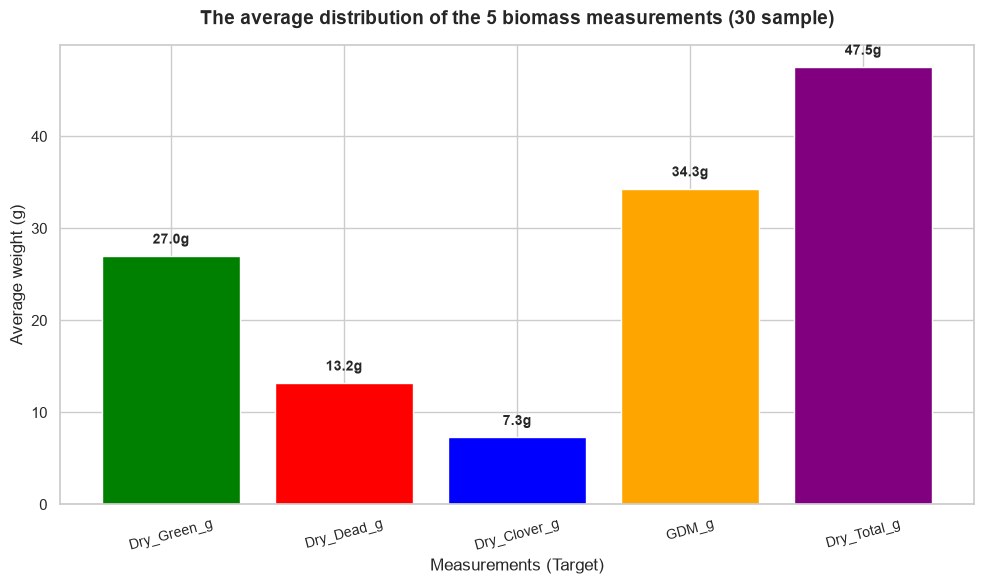

In [30]:
# Average values for the 30 samples for the 5 measurements
mean_values = [train_small_csv[train_small_csv['target_name'] == target]['target'].mean()
    for target in TARGETS]

# Create figure
plt.figure(figsize=(10, 6))
sns.set_theme(style='whitegrid')

# Barplot
bars = plt.bar(TARGETS, mean_values, color=['green', 'red', 'blue', 'orange', 'purple'])

# Labels and design
plt.title('The average distribution of the 5 biomass measurements (30 sample)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Measurements (Target)', fontsize=12)
plt.ylabel('Average weight (g)', fontsize=12)
plt.xticks(rotation=15, fontsize=10)

# Writing values on the top of the bars
for bar in bars:
  height = bar.get_height()
  plt.text(bar.get_x() + bar.get_width()/2.0, height + 1, f'{height:.1f}g',
      ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

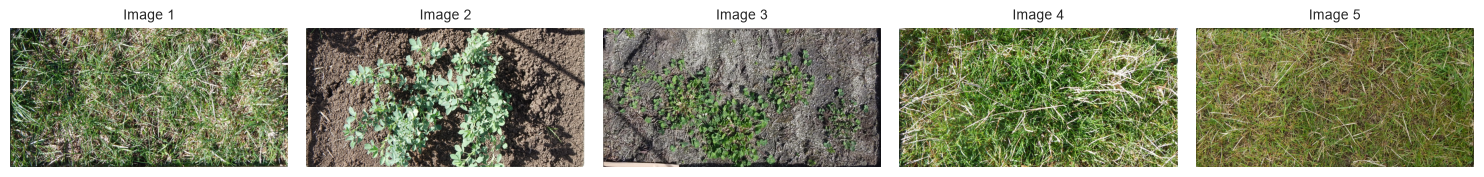

In [31]:
# First 5 images for visualization
# We choose the paths of the first 5 images from train_small_csv
first_5_paths = train_small_csv['image_path'].unique()[:5]

# Create a figure for display the 5 images in a row
plt.figure(figsize=(15, 10))

for i, img_path in enumerate(first_5_paths):
  try:
    # Open the image
    img = Image.open(img_path)
    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.axis('off')  # turning off axis for better view
    plt.title(f'Image {i+1}', fontsize=10)
  except Exception as e:
    print(f'Error during loading the image ({img_path}): {e}')

plt.tight_layout()
plt.show()

In [32]:
# After inspecting the dataset, we can start forming it to the training
train_wide = train_small_csv.pivot(
    index='image_path',
    columns='target_name',
    values='target',
).reset_index()

missing_targets = set(TARGETS) - set(train_wide.columns)
if missing_targets:
    raise ValueError(f'Missing training targets: {missing_targets}')

train_wide = train_wide[['image_path'] + TARGETS]

print(f'Wide training table shape: {train_wide.shape}')
print('One row per image, with its five target values:')
display(train_wide.head(5))

Wide training table shape: (30, 6)
One row per image, with its five target values:


target_name,image_path,Dry_Green_g,Dry_Dead_g,Dry_Clover_g,GDM_g,Dry_Total_g
0,c:\Users\User\Documents\MSc\Deep_learning_Pyth...,16.2751,31.9984,0.0000,16.2750,48.2735
1,c:\Users\User\Documents\MSc\Deep_learning_Pyth...,7.6000,0.0000,0.0000,7.6000,7.6000
2,c:\Users\User\Documents\MSc\Deep_learning_Pyth...,0.0000,0.0000,6.0500,6.0500,6.0500
3,c:\Users\User\Documents\MSc\Deep_learning_Pyth...,24.2376,30.9703,0.0000,24.2376,55.2079
4,c:\Users\User\Documents\MSc\Deep_learning_Pyth...,10.5261,23.2239,0.4343,10.9605,34.1844


In [33]:
def resolve_paths(relative_or_absolute_paths):
  paths = []
  for path in relative_or_absolute_paths:
    p = Path(path)
    if not p.is_absolute():
      p = DATA_DIR / path
    if not p.is_file():
      raise FileNotFoundError(f'Image not found: {p}')
    paths.append(str(p))
  return np.asarray(paths)


image_paths = resolve_paths(train_wide['image_path'].tolist())
targets = train_wide[TARGETS].to_numpy(dtype=np.float32)

# Train-test (/validation) split
train_paths, val_paths, y_train, y_val = train_test_split(
    image_paths, targets, test_size=0.2, random_state=SEED)

print(f'Train images: {len(train_paths)} | Validation images: {len(val_paths)}')

Train images: 24 | Validation images: 6


In [34]:
# Effectively loads the pictures into the model
def load_image(path):
  image = tf.io.read_file(path)
  image = tf.io.decode_jpeg(image, channels=3)
  image = tf.image.resize_with_pad(image, IMAGE_SIZE, IMAGE_SIZE)
  return tf.cast(image, tf.float32)


def make_dataset(paths, labels=None, training=False):
  if labels is None:
    dataset = tf.data.Dataset.from_tensor_slices(paths)
    dataset = dataset.map(
        lambda path: {'image': load_image(path)},
        num_parallel_calls=tf.data.AUTOTUNE)
  else:
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(
        lambda path, label: ({'image': load_image(path)}, label),
        num_parallel_calls=tf.data.AUTOTUNE)
  if training:
    dataset = dataset.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
  return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(train_paths, y_train, training=True)
val_ds = make_dataset(val_paths, y_val)

In [35]:
# It is necessary for our loss measure, but we will
# will use it in the training code (2nd milestone)
def weighted_mse(y_true, y_pred):
  squared_error = tf.square(y_true - y_pred)
  return tf.reduce_sum(
      squared_error * TARGET_WEIGHTS, axis=-1
  ) / tf.reduce_sum(TARGET_WEIGHTS)

# A little bit of augmentation
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.06),
    tf.keras.layers.RandomZoom(0.08),
], name='augmentation')